# Homework 5

## 1. Decision Trees as Interpretable Models

### (a) Load and Check the Data

I use the Acute Inflammations data to build a decision tree.
The data have six input features and two diagnosis labels.
I combine the two labels into one class using the label powerset method.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Python:", sys.executable)
print("Working directory:", Path.cwd())
print("Scikit-learn version:", sklearn.__version__)

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

print("Data folder:", data_dir.resolve())
print("Data folder exists:", data_dir.is_dir())

Python: C:\Users\19098\DSCI-552\.venv\Scripts\python.exe
Working directory: C:\Users\19098\DSCI-552\Homework5
Scikit-learn version: 1.9.1
Data folder: C:\Users\19098\DSCI-552\Homework5\data
Data folder exists: True


In [2]:
data_files = sorted(
    path for path in data_dir.rglob("*")
    if path.is_file() and path.suffix.lower() != ".zip"
)

print("Number of files:", len(data_files))

for path in data_files:
    print(path.relative_to(data_dir))

Number of files: 5
communities.data
communities.names
diagnosis.data
diagnosis.names
Simplifying Decision Tree Interpretability with Python & Scikit-learn - KDnuggets.pdf


In [3]:
diagnosis_path = data_dir / "diagnosis.data"

columns = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "urethra_burning",
    "bladder_inflammation",
    "renal_pelvis_nephritis",
]

raw_bytes = diagnosis_path.read_bytes()
encoding = (
    "utf-16"
    if raw_bytes.startswith((b"\xff\xfe", b"\xfe\xff"))
    else "utf-8-sig"
)

acute = pd.read_csv(
    diagnosis_path,
    sep=r"\s+",
    header=None,
    encoding=encoding,
    dtype=str,
)

assert acute.shape[1] == 8, "Expected 8 columns."
acute.columns = columns

acute["temperature"] = pd.to_numeric(
    acute["temperature"].str.replace(",", ".", regex=False)
)

for column in columns[1:]:
    acute[column] = acute[column].str.strip().str.lower()

print("Data shape:", acute.shape)
print("Missing values:", acute.isna().sum().sum())

display(acute.head())

Data shape: (120, 8)
Missing values: 0


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,urethra_burning,bladder_inflammation,renal_pelvis_nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


In [4]:
for column in columns[1:]:
    assert acute[column].isin(["yes", "no"]).all(), (
        f"Unexpected value in {column}"
    )

acute_numeric = acute.copy()

for column in columns[1:]:
    acute_numeric[column] = acute[column].map({"no": 0, "yes": 1})

X_acute = acute_numeric[columns[:6]].copy()

diagnosis_labels = acute_numeric[columns[6:]].copy()

y_acute = (
    diagnosis_labels["bladder_inflammation"].astype(str)
    + diagnosis_labels["renal_pelvis_nephritis"].astype(str)
)

y_acute.name = "diagnosis_class"

print("Feature shape:", X_acute.shape)
print("Target shape:", y_acute.shape)
print("\nClass counts:")
print(y_acute.value_counts().sort_index())

display(X_acute.head())

Feature shape: (120, 6)
Target shape: (120,)

Class counts:
diagnosis_class
00    30
01    31
10    40
11    19
Name: count, dtype: int64


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,urethra_burning
0,35.5,0,1,0,0,0
1,35.9,0,0,1,1,1
2,35.9,0,1,0,0,0
3,36.0,0,0,1,1,1
4,36.0,0,1,0,0,0


### (b) Build and Plot a Decision Tree

I train a decision tree on the whole dataset, as the question asks.
The tree uses six features to predict the combined diagnosis class.
I first build the tree without pruning.

The first digit shows bladder inflammation.
The second digit shows renal pelvis nephritis.
For each digit, 0 means no and 1 means yes.

In [5]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

full_tree = DecisionTreeClassifier(
    criterion="gini",
    random_state=42,
    ccp_alpha=0.0,
)

full_tree.fit(X_acute, y_acute)

train_predictions = full_tree.predict(X_acute)
train_accuracy = accuracy_score(y_acute, train_predictions)

print("Training accuracy:", f"{train_accuracy:.4f}")
print("Tree depth:", full_tree.get_depth())
print("Number of leaves:", full_tree.get_n_leaves())
print("Number of nodes:", full_tree.tree_.node_count)
print("Class order:", full_tree.classes_)

Training accuracy: 1.0000
Tree depth: 4
Number of leaves: 6
Number of nodes: 11
Class order: ['00' '01' '10' '11']


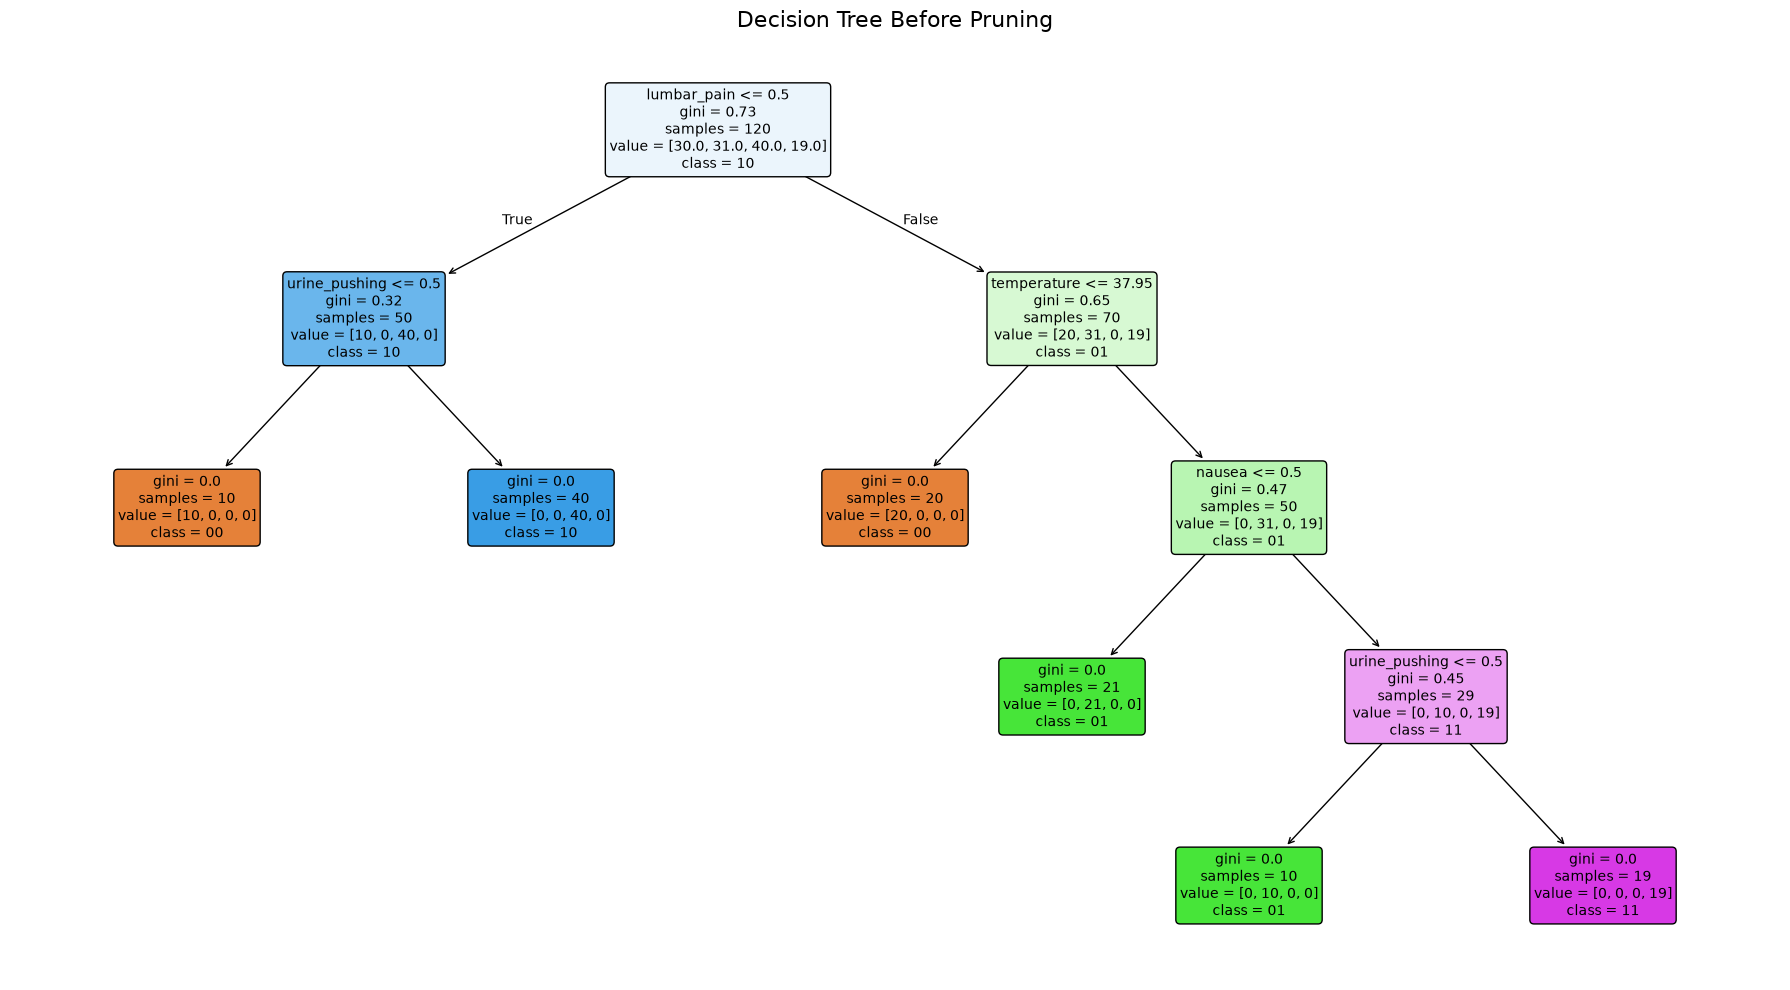

In [6]:
fig, ax = plt.subplots(figsize=(18, 10))

plot_tree(
    full_tree,
    feature_names=X_acute.columns.tolist(),
    class_names=full_tree.classes_.tolist(),
    filled=True,
    rounded=True,
    impurity=True,
    precision=2,
    fontsize=10,
    ax=ax,
)

ax.set_title("Decision Tree Before Pruning", fontsize=16)
plt.tight_layout()
plt.show()

### (c) Convert the Tree to IF–THEN Rules

Each path from the root to a leaf gives one rule.
The conditions on the path form the IF part.
The predicted class at the leaf forms the THEN part.

The tree has six leaves, so it gives six rules.
It correctly predicts all 120 training records.
This does not show how well it will predict new records.

In [7]:
def get_tree_rules(model, feature_names):
    tree = model.tree_
    rules = []

    def walk(node, conditions):
        left = tree.children_left[node]
        right = tree.children_right[node]

        if left == right:
            class_index = np.argmax(tree.value[node][0])
            label = str(model.classes_[class_index])

            bladder = "Yes" if label[0] == "1" else "No"
            kidney = "Yes" if label[1] == "1" else "No"

            condition_text = " AND ".join(conditions) or "True"

            rule = (
                f"IF {condition_text}\n"
                f"THEN bladder inflammation = {bladder}, "
                f"renal pelvis nephritis = {kidney} "
                f"(class {label}).\n"
                f"Training records in this leaf: "
                f"{tree.n_node_samples[node]}"
            )

            rules.append(rule)
            return

        feature = feature_names[tree.feature[node]]
        threshold = tree.threshold[node]

        if feature != "temperature" and threshold == 0.5:
            left_condition = f"{feature} = No"
            right_condition = f"{feature} = Yes"
        else:
            left_condition = f"{feature} <= {threshold:.2f}"
            right_condition = f"{feature} > {threshold:.2f}"

        walk(left, conditions + [left_condition])
        walk(right, conditions + [right_condition])

    walk(0, [])
    return rules


full_tree_rules = get_tree_rules(
    full_tree,
    X_acute.columns.tolist(),
)

print("Number of rules:", len(full_tree_rules))

for number, rule in enumerate(full_tree_rules, start=1):
    print(f"\nRule {number}")
    print(rule)

Number of rules: 6

Rule 1
IF lumbar_pain = No AND urine_pushing = No
THEN bladder inflammation = No, renal pelvis nephritis = No (class 00).
Training records in this leaf: 10

Rule 2
IF lumbar_pain = No AND urine_pushing = Yes
THEN bladder inflammation = Yes, renal pelvis nephritis = No (class 10).
Training records in this leaf: 40

Rule 3
IF lumbar_pain = Yes AND temperature <= 37.95
THEN bladder inflammation = No, renal pelvis nephritis = No (class 00).
Training records in this leaf: 20

Rule 4
IF lumbar_pain = Yes AND temperature > 37.95 AND nausea = No
THEN bladder inflammation = No, renal pelvis nephritis = Yes (class 01).
Training records in this leaf: 21

Rule 5
IF lumbar_pain = Yes AND temperature > 37.95 AND nausea = Yes AND urine_pushing = No
THEN bladder inflammation = No, renal pelvis nephritis = Yes (class 01).
Training records in this leaf: 10

Rule 6
IF lumbar_pain = Yes AND temperature > 37.95 AND nausea = Yes AND urine_pushing = Yes
THEN bladder inflammation = Yes, re

### (d) Cost-Complexity Pruning

I use cost-complexity pruning to make the tree smaller.
The parameter ccp_alpha controls pruning.
A larger alpha gives a stronger penalty for extra leaves.

I compare the number of leaves, tree depth, and training accuracy.
A smaller tree is easier to explain, but it may make more mistakes.

In [8]:
pruning_path = full_tree.cost_complexity_pruning_path(
    X_acute,
    y_acute,
)

alphas = np.unique(pruning_path.ccp_alphas)

pruning_models = []
pruning_rows = []

for alpha in alphas:
    model = DecisionTreeClassifier(
        criterion="gini",
        random_state=42,
        ccp_alpha=float(alpha),
    )

    model.fit(X_acute, y_acute)
    predictions = model.predict(X_acute)

    pruning_models.append(model)

    pruning_rows.append({
        "alpha": float(alpha),
        "depth": model.get_depth(),
        "leaves": model.get_n_leaves(),
        "nodes": model.tree_.node_count,
        "training_accuracy": accuracy_score(
            y_acute, predictions
        ),
        "training_errors": int(
            np.sum(predictions != y_acute.to_numpy())
        ),
    })

pruning_results = pd.DataFrame(pruning_rows)
pruning_results.index.name = "model_id"

display(pruning_results.round(6))

,alpha,depth,leaves,nodes,training_accuracy,training_errors
model_id,,,,,,
0,0.000000,4,6,11,1.000000,0
1,0.098167,2,4,7,0.841667,19
2,0.133333,2,3,5,0.758333,29
3,0.182000,1,2,3,0.591667,49
4,0.222917,0,1,1,0.333333,80


#### Choose a Smaller Tree

For this example, I choose the smallest tree on the pruning path
with at least 80% training accuracy. This cutoff is my choice,
not a requirement in the question.

The selected tree has four leaves and a depth of two.
Its training accuracy is 84.17%, with 19 errors.
The full tree has six leaves, a depth of four, and no training errors.

The smaller tree is easier to read, but it loses accuracy.

Selected alpha: 0.098167
Tree depth: 2
Number of leaves: 4
Training accuracy: 0.8417


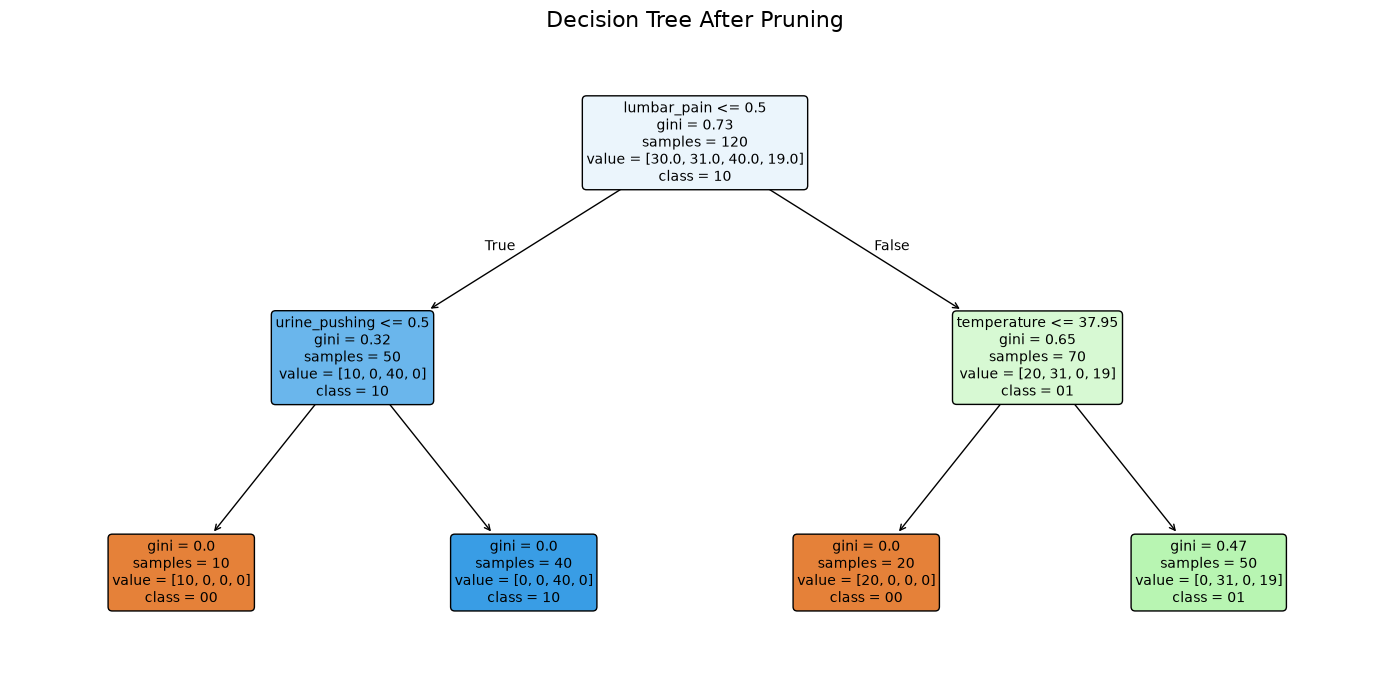

In [9]:
eligible_trees = pruning_results[
    pruning_results["training_accuracy"] >= 0.80
]

selected_id = int(
    eligible_trees.sort_values(
        ["leaves", "depth", "alpha"]
    ).index[0]
)

pruned_tree = pruning_models[selected_id]
selected_alpha = pruning_results.loc[selected_id, "alpha"]

print("Selected alpha:", f"{selected_alpha:.6f}")
print("Tree depth:", pruned_tree.get_depth())
print("Number of leaves:", pruned_tree.get_n_leaves())
print(
    "Training accuracy:",
    f"{pruned_tree.score(X_acute, y_acute):.4f}",
)

fig, ax = plt.subplots(figsize=(14, 7))

plot_tree(
    pruned_tree,
    feature_names=X_acute.columns.tolist(),
    class_names=pruned_tree.classes_.tolist(),
    filled=True,
    rounded=True,
    precision=2,
    fontsize=10,
    ax=ax,
)

ax.set_title("Decision Tree After Pruning", fontsize=16)
plt.tight_layout()
plt.show()

In [10]:
pruned_rules = get_tree_rules(
    pruned_tree,
    X_acute.columns.tolist(),
)

print("Number of rules:", len(pruned_rules))

for number, rule in enumerate(pruned_rules, start=1):
    print(f"\nRule {number}")
    print(rule)

pruned_predictions = pd.Series(
    pruned_tree.predict(X_acute),
    index=y_acute.index,
    name="Predicted",
)

print("\nTraining confusion matrix:")

display(
    pd.crosstab(
        y_acute.rename("Actual"),
        pruned_predictions,
    ).reindex(
        index=full_tree.classes_,
        columns=full_tree.classes_,
        fill_value=0,
    )
)

Number of rules: 4

Rule 1
IF lumbar_pain = No AND urine_pushing = No
THEN bladder inflammation = No, renal pelvis nephritis = No (class 00).
Training records in this leaf: 10

Rule 2
IF lumbar_pain = No AND urine_pushing = Yes
THEN bladder inflammation = Yes, renal pelvis nephritis = No (class 10).
Training records in this leaf: 40

Rule 3
IF lumbar_pain = Yes AND temperature <= 37.95
THEN bladder inflammation = No, renal pelvis nephritis = No (class 00).
Training records in this leaf: 20

Rule 4
IF lumbar_pain = Yes AND temperature > 37.95
THEN bladder inflammation = No, renal pelvis nephritis = Yes (class 01).
Training records in this leaf: 50

Training confusion matrix:


Predicted,00,01,10,11
Actual,,,,
00,30,0,0,0
01,0,31,0,0
10,0,0,40,0
11,0,19,0,0


#### Results

With alpha about 0.098167, the tree has four leaves and a depth of two.
It correctly predicts 101 of the 120 records, giving 84.17% training accuracy.

All 19 errors come from class 11 being predicted as class 01.
The pruned tree never predicts class 11.
It misses bladder inflammation in records that have both diagnoses.

This is the smallest tree on the pruning path that meets my 80% training
accuracy cutoff. It has fewer and shorter rules, but it loses useful detail.
If I want to keep zero training errors, I must keep the full tree on this path.

These results are based on the training data.
They do not measure accuracy on new data.

## 2. LASSO and Boosting for Regression

### (a) Load the Data and Create the Train/Test Split

I use the Communities and Crime data.
The target is ViolentCrimesPerPop.

I use the first 1,495 records for training and the remaining records for testing.
I keep the original row order.

I remove five columns that are not input features:
state, county, community, communityname, and fold.
I read question marks as missing values.

In [11]:
names_path = data_dir / "communities.names"
names_text = names_path.read_text(encoding="utf-8-sig")

crime_columns = []

for line in names_text.splitlines():
    line = line.strip()

    if line.lower().startswith("@attribute"):
        column_name = line.split()[1].strip("'\"")
        crime_columns.append(column_name)

print("Number of column names:", len(crime_columns))

assert len(crime_columns) == 128, "Expected 128 column names."

crime = pd.read_csv(
    data_dir / "communities.data",
    header=None,
    na_values=["?"],
)

assert crime.shape[1] == len(crime_columns), (
    "The data and column names do not match."
)

crime.columns = crime_columns

print("Data shape:", crime.shape)
print("Target column:", crime.columns[-1])

display(crime.head())

Number of column names: 128
Data shape: (1994, 128)
Target column: ViolentCrimesPerPop


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [12]:
id_columns = [
    "state",
    "county",
    "community",
    "communityname",
    "fold",
]

target_column = "ViolentCrimesPerPop"

X_crime = crime.drop(
    columns=id_columns + [target_column]
).apply(pd.to_numeric, errors="raise")

y_crime = pd.to_numeric(
    crime[target_column],
    errors="raise",
)

assert y_crime.notna().all(), "The target has missing values."

X_train = X_crime.iloc[:1495].copy()
X_test = X_crime.iloc[1495:].copy()

y_train = y_crime.iloc[:1495].copy()
y_test = y_crime.iloc[1495:].copy()

print("Training feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Test target shape:", y_test.shape)

print("\nMissing input values in training:", X_train.isna().sum().sum())
print("Missing input values in testing:", X_test.isna().sum().sum())
print("Features with missing training values:", X_train.isna().any().sum())
print("Features with all training values missing:", X_train.isna().all().sum())

Training feature shape: (1495, 122)
Test feature shape: (499, 122)
Training target shape: (1495,)
Test target shape: (499,)

Missing input values in training: 27633
Missing input values in testing: 9218
Features with missing training values: 23
Features with all training values missing: 0


### (b) Fill Missing Values

I fill missing values with the median of each feature.
The median is less affected by extreme values than the mean.

I calculate the medians using only the training data.
I use the same medians to fill missing values in the test data.
No feature is completely missing in the training set.

For cross-validation later, I will fit the imputer inside each
training fold using a pipeline.

In [13]:
from sklearn.impute import SimpleImputer

crime_imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    crime_imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index,
)

X_test_imputed = pd.DataFrame(
    crime_imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index,
)

missing_summary = pd.DataFrame({
    "train_missing": X_train.isna().sum(),
    "test_missing": X_test.isna().sum(),
    "training_median": crime_imputer.statistics_,
})

missing_summary = missing_summary.loc[
    (missing_summary["train_missing"] > 0)
    | (missing_summary["test_missing"] > 0)
].sort_values("train_missing", ascending=False)

display(missing_summary)

print(
    "Training missing values after filling:",
    X_train_imputed.isna().sum().sum(),
)
print(
    "Test missing values after filling:",
    X_test_imputed.isna().sum().sum(),
)

print("Training shape:", X_train_imputed.shape)
print("Test shape:", X_test_imputed.shape)

assert not X_train_imputed.isna().any().any()
assert not X_test_imputed.isna().any().any()
assert X_train_imputed.shape == X_train.shape
assert X_test_imputed.shape == X_test.shape

,train_missing,test_missing,training_median
LemasSwornFT,1256,419,0.02
LemasSwFTPerPop,1256,419,0.18
LemasSwFTFieldOps,1256,419,0.97
LemasTotalReq,1256,419,0.04
LemasSwFTFieldPerPop,1256,419,0.21
LemasTotReqPerPop,1256,419,0.17
PolicReqPerOffic,1256,419,0.30
OfficAssgnDrugUnits,1256,419,0.04
PolicPerPop,1256,419,0.18
RacialMatchCommPol,1256,419,0.73


Training missing values after filling: 0
Test missing values after filling: 0
Training shape: (1495, 122)
Test shape: (499, 122)


### (c) Correlation Matrix

I calculate Pearson correlations between the input features
using the filled training data.

Values close to 1 show a strong positive linear relationship.
Values close to -1 show a strong negative linear relationship.
Values close to 0 show a weak linear relationship.

Many values in some features were filled with the median.
This can affect their correlations.

Correlation matrix shape: (122, 122)


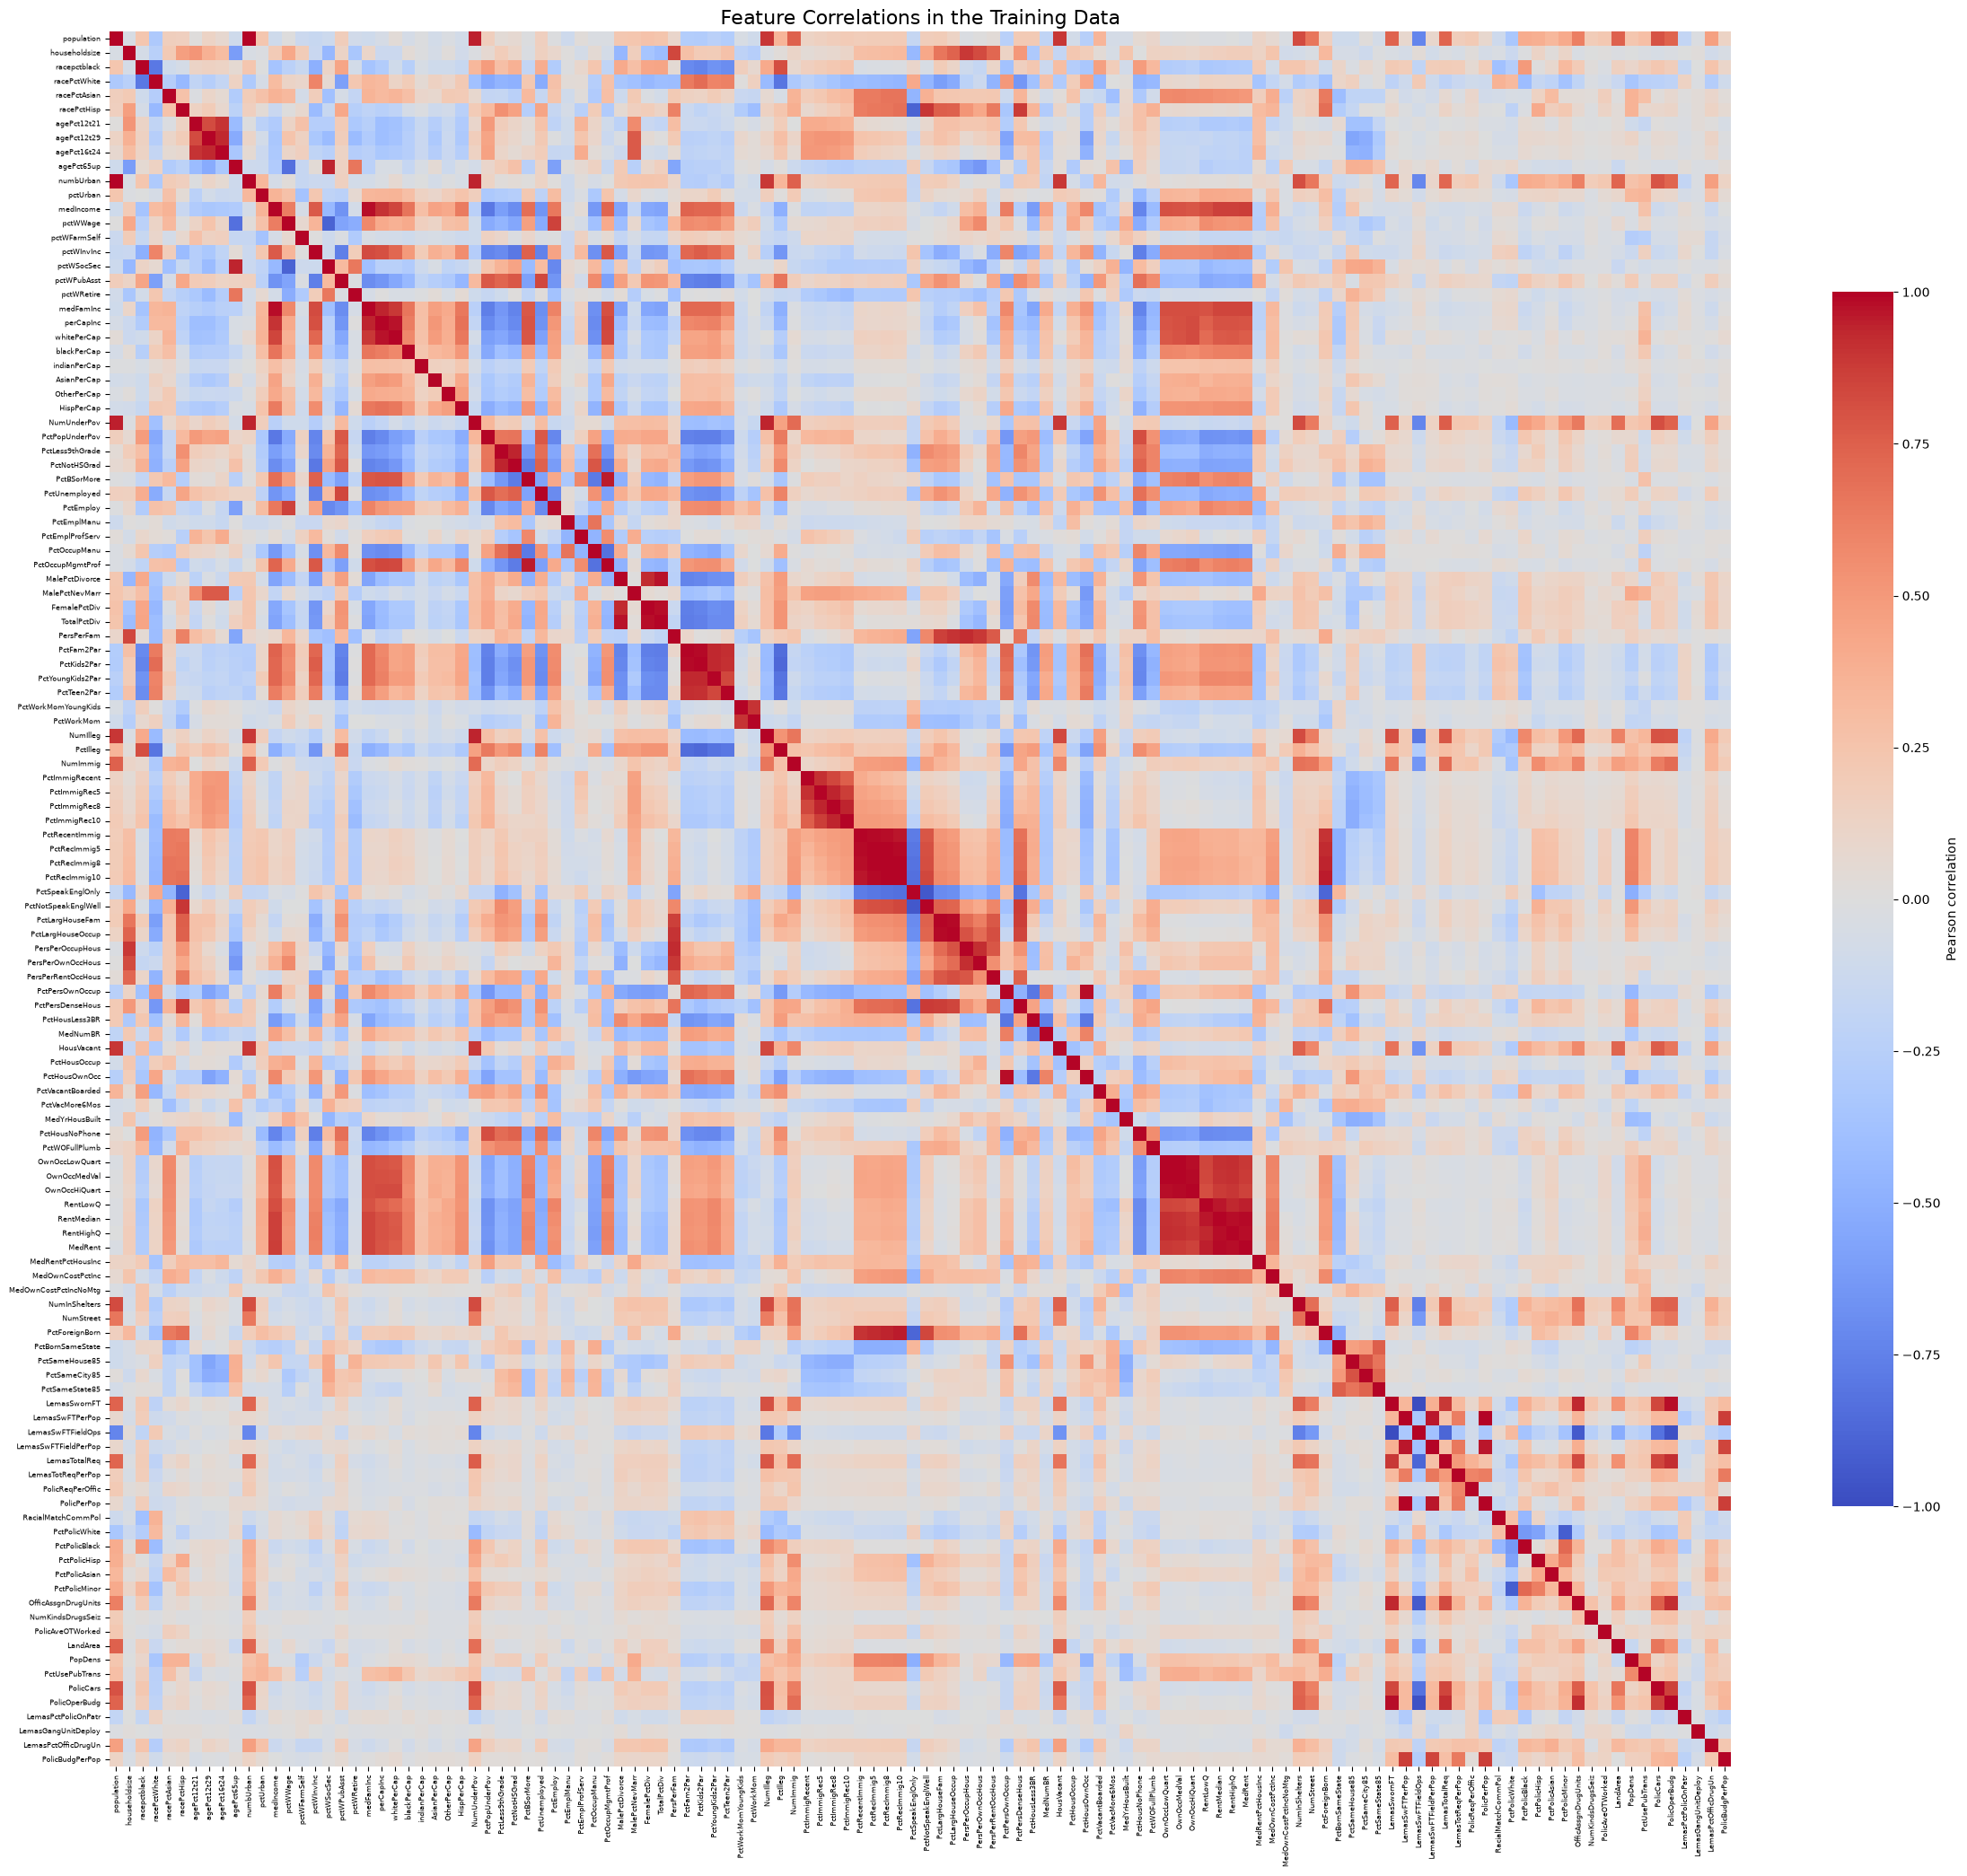

In [14]:
feature_corr = X_train_imputed.corr(method="pearson")

print("Correlation matrix shape:", feature_corr.shape)

fig, ax = plt.subplots(figsize=(24, 21))

sns.heatmap(
    feature_corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={"label": "Pearson correlation", "shrink": 0.7},
    ax=ax,
)

ax.set_title("Feature Correlations in the Training Data", fontsize=16)
ax.tick_params(axis="x", labelsize=6, rotation=90)
ax.tick_params(axis="y", labelsize=6, rotation=0)

plt.tight_layout()
plt.show()

In [15]:
upper_triangle = np.triu(
    np.ones(feature_corr.shape, dtype=bool),
    k=1,
)

correlation_pairs = (
    feature_corr.where(upper_triangle)
    .stack()
    .rename("correlation")
    .reset_index()
)

correlation_pairs.columns = [
    "feature_1",
    "feature_2",
    "correlation",
]

correlation_pairs["absolute_correlation"] = (
    correlation_pairs["correlation"].abs()
)

top_correlation_pairs = correlation_pairs.sort_values(
    "absolute_correlation",
    ascending=False,
).head(10)

display(top_correlation_pairs.round(4))

,feature_1,feature_2,correlation,absolute_correlation
11937,LemasSwFTPerPop,PolicPerPop,1.0000,1.0000
7135,PctRecImmig8,PctRecImmig10,0.9956,0.9956
9718,OwnOccLowQuart,OwnOccMedVal,0.9947,0.9947
11810,LemasSwornFT,LemasSwFTFieldOps,-0.9945,0.9945
10,population,numbUrban,0.9936,0.9936
7012,PctRecImmig5,PctRecImmig8,0.9927,0.9927
9841,OwnOccMedVal,OwnOccHiQuart,0.9916,0.9916
6889,PctRecentImmig,PctRecImmig5,0.9894,0.9894
10211,RentMedian,MedRent,0.9888,0.9888
5290,PctFam2Par,PctKids2Par,0.9856,0.9856


Several feature pairs have correlations close to 1 or -1.
For example, OwnOccLowQuart and OwnOccMedVal have a correlation
of about 0.9947.

These features contain similar information.
Strong relationships between input features can make linear
regression coefficients unstable. This is called multicollinearity.

### (d) Coefficient of Variation

I calculate the coefficient of variation for each input feature:

CV = sample standard deviation / mean

I use the filled training data and calculate the sample standard
deviation with ddof=1.

A larger CV means more spread compared with the mean.
It does not mean the feature is better at predicting the target.
If the mean is zero, the CV is undefined.

In [16]:
feature_means = X_train_imputed.mean()
feature_stds = X_train_imputed.std(ddof=1)

safe_means = feature_means.replace(0, np.nan)

cv_table = pd.DataFrame({
    "mean": feature_means,
    "sample_std": feature_stds,
    "coefficient_of_variation": feature_stds / safe_means,
})

cv_table.index.name = "feature"

cv_table = cv_table.sort_values(
    "coefficient_of_variation",
    ascending=False,
    na_position="last",
)

print("Number of features:", len(cv_table))
print(
    "Features with undefined CV:",
    cv_table["coefficient_of_variation"].isna().sum(),
)

with pd.option_context("display.max_rows", None):
    display(cv_table.round(4))

Number of features: 122
Features with undefined CV: 0


,mean,sample_std,coefficient_of_variation
feature,,,
PctPolicAsian,0.0163,0.0898,5.5271
NumStreet,0.0230,0.0987,4.2929
NumInShelters,0.0296,0.1027,3.4710
NumIlleg,0.0372,0.1138,3.0590
NumImmig,0.0306,0.0895,2.9266
LemasPctOfficDrugUn,0.0933,0.2382,2.5529
NumUnderPov,0.0568,0.1332,2.3424
LemasSwornFT,0.0287,0.0646,2.2480
population,0.0582,0.1304,2.2411


### (e) Scatter Plots and Box Plots

I select the 11 features with the highest coefficients of variation.

For each scatter plot, the x-axis shows the feature and the y-axis
shows ViolentCrimesPerPop. The box plots show the spread of the
selected features.

I use only the training data for these plots.

In [17]:
n_selected = int(np.sqrt(128))

top_cv_features = (
    cv_table.dropna(subset=["coefficient_of_variation"])
    .head(n_selected)
    .index.tolist()
)

print("Number of selected features:", len(top_cv_features))

display(cv_table.loc[top_cv_features].round(4))

Number of selected features: 11


,mean,sample_std,coefficient_of_variation
feature,,,
PctPolicAsian,0.0163,0.0898,5.5271
NumStreet,0.0230,0.0987,4.2929
NumInShelters,0.0296,0.1027,3.4710
NumIlleg,0.0372,0.1138,3.0590
NumImmig,0.0306,0.0895,2.9266
LemasPctOfficDrugUn,0.0933,0.2382,2.5529
NumUnderPov,0.0568,0.1332,2.3424
LemasSwornFT,0.0287,0.0646,2.2480
population,0.0582,0.1304,2.2411


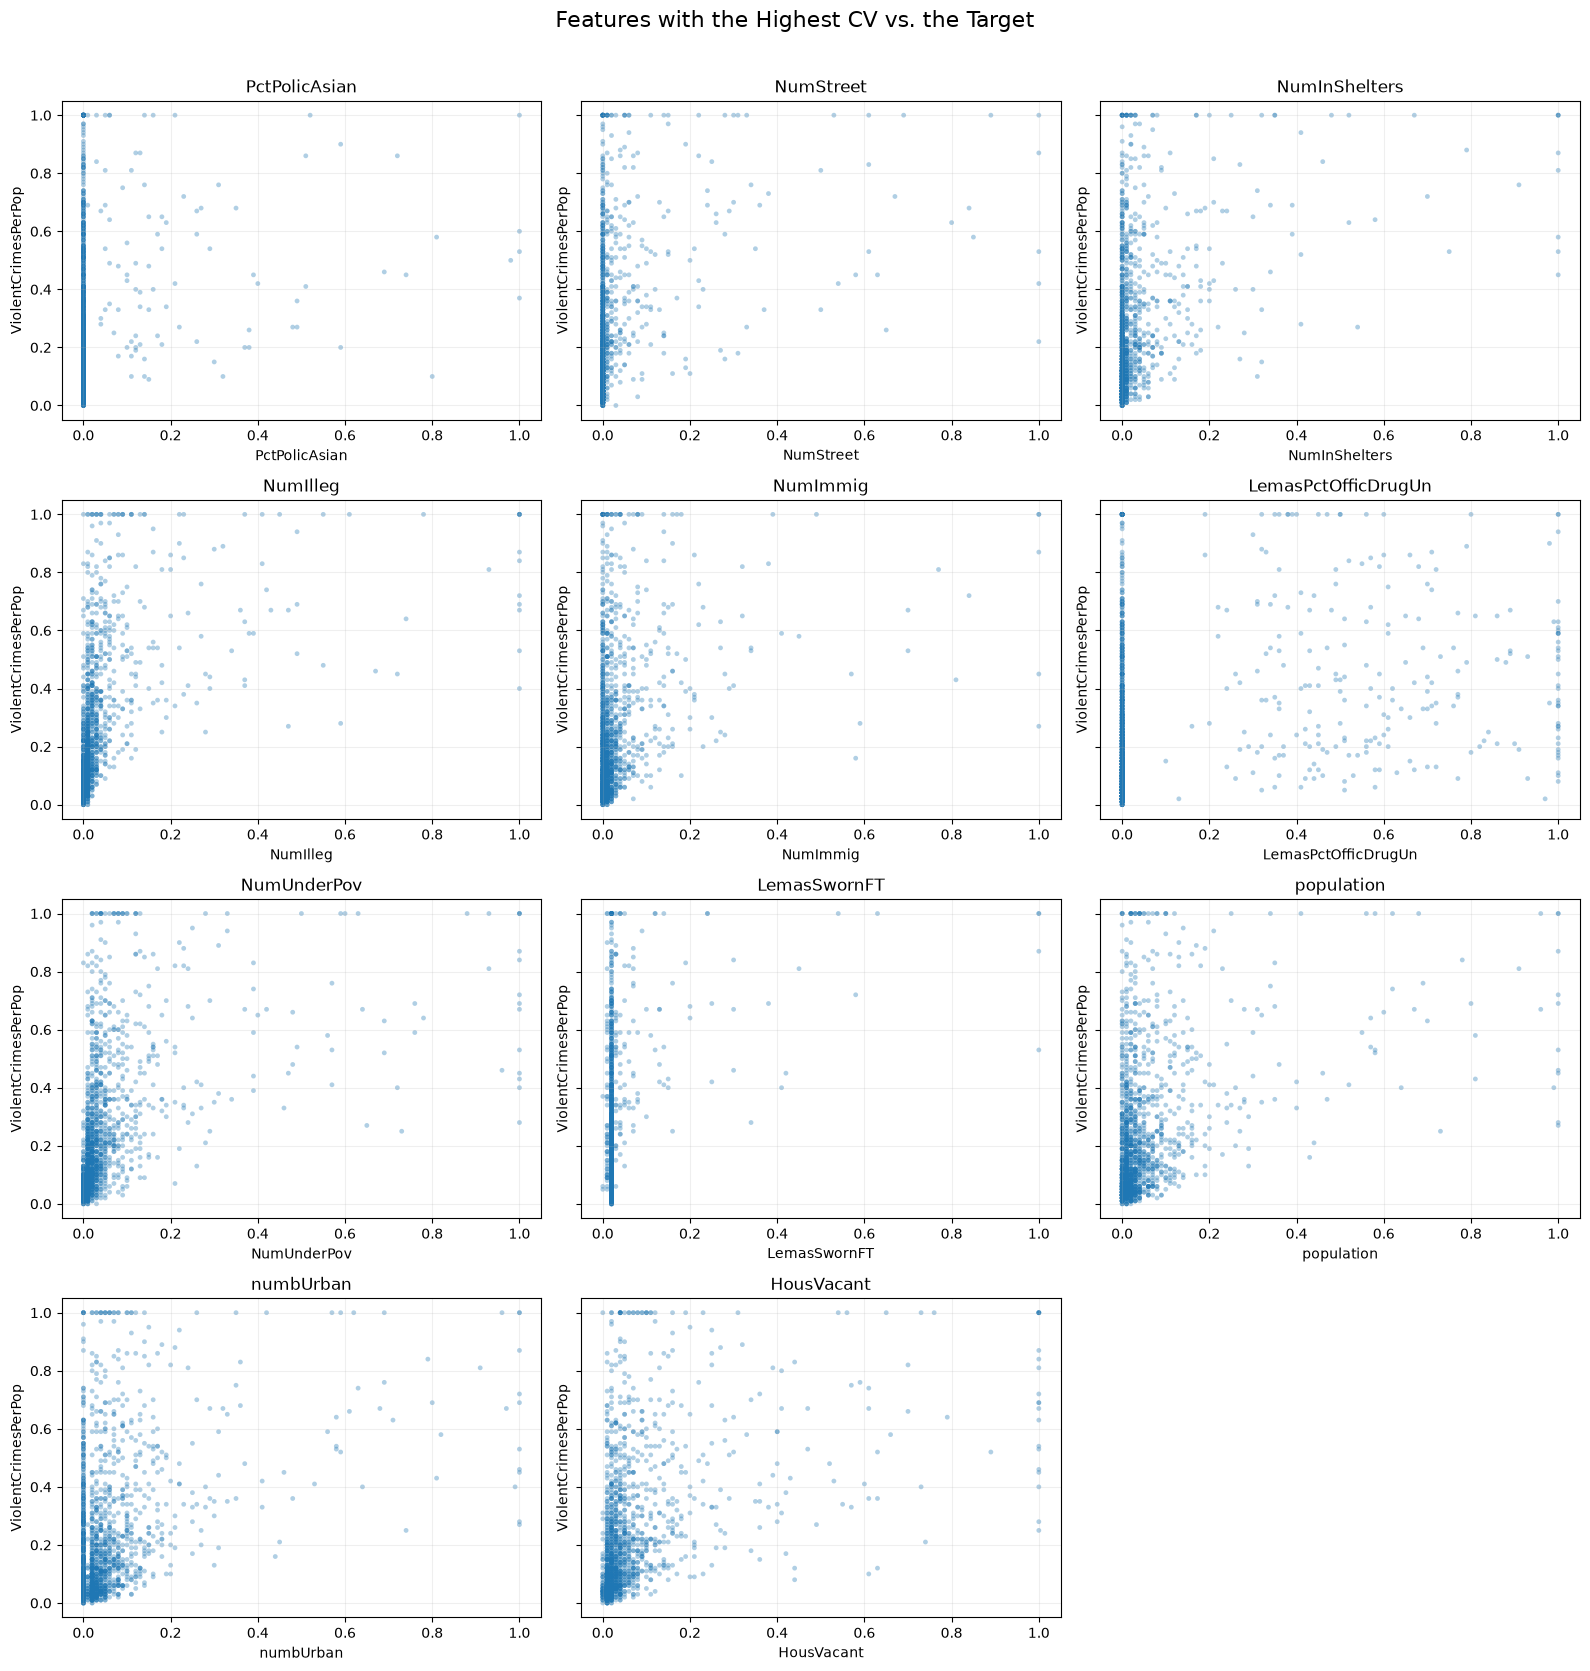

In [18]:
fig, axes = plt.subplots(
    4, 3,
    figsize=(16, 17),
    sharey=True,
)

for ax, feature in zip(axes.flat, top_cv_features):
    ax.scatter(
        X_train_imputed[feature],
        y_train,
        s=12,
        alpha=0.35,
        edgecolors="none",
    )

    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("ViolentCrimesPerPop")
    ax.grid(alpha=0.2)

for ax in axes.flat[len(top_cv_features):]:
    ax.set_visible(False)

fig.suptitle(
    "Features with the Highest CV vs. the Target",
    fontsize=16,
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

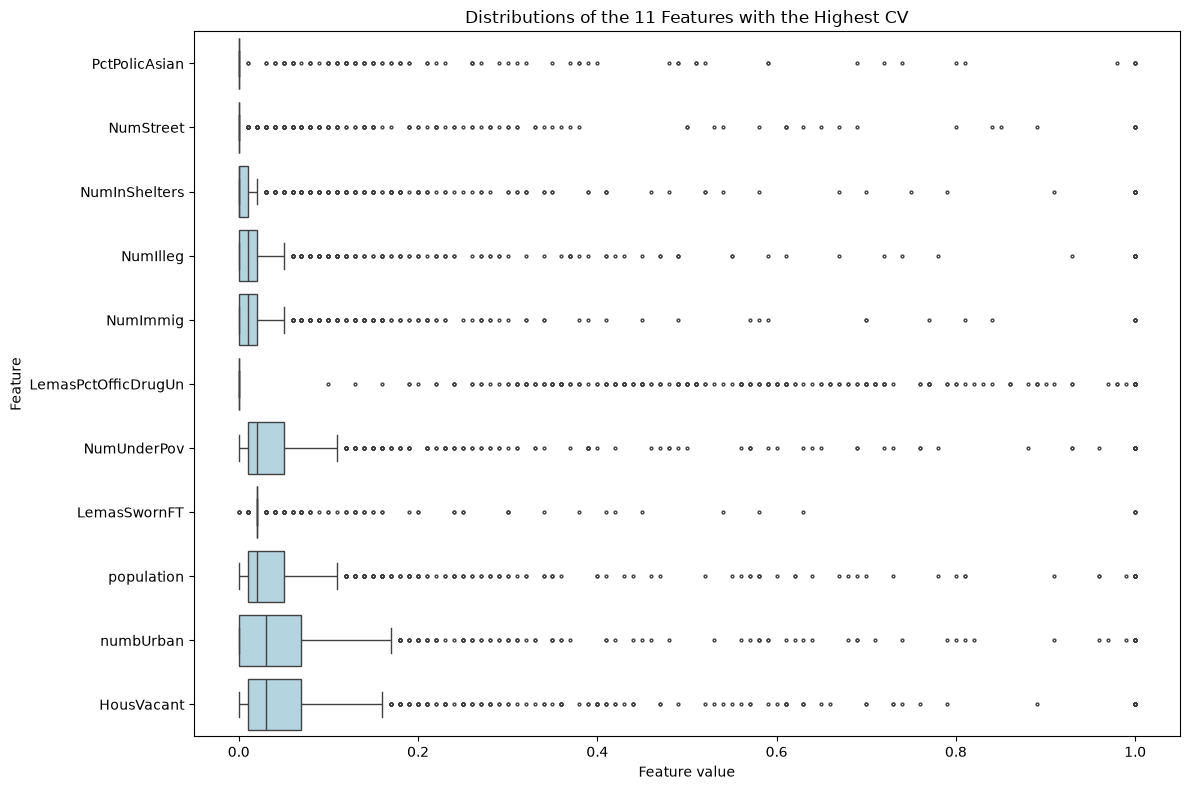

In [19]:
fig, ax = plt.subplots(figsize=(12, 8))

sns.boxplot(
    data=X_train_imputed[top_cv_features],
    orient="h",
    color="lightblue",
    fliersize=2,
    ax=ax,
)

ax.set_title("Distributions of the 11 Features with the Highest CV")
ax.set_xlabel("Feature value")
ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()

#### Can Scatter Plots Show Statistical Significance?

No. Scatter plots can show patterns, possible relationships, and outliers,
but they cannot prove statistical significance.

A feature with a high CV is not necessarily useful for predicting the target.
A statistical test or a suitable regression analysis is needed to assess
significance under its assumptions.

These 11 features are selected only for this plotting step.
I keep all 122 input features for the regression models that follow.

#### Plot Observations

Several selected features have small values for most records,
with some much larger values. Their distributions have long right tails.

PctPolicAsian and LemasSwornFT also contain many values filled
with the training median. This affects their distributions.

A high CV shows a large spread relative to the mean.
It does not prove that a feature is statistically significant.

### (f) Ordinary Least Squares Regression

I fit an ordinary least squares model using all 122 input features.
The model learns from the training set and predicts the test set.

I report test mean squared error (MSE) as the test error.
I also report test RMSE and R-squared.

The pipeline fills missing values using medians learned
from the training data.

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

ols_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", LinearRegression()),
])

ols_model.fit(X_train, y_train)

ols_train_pred = ols_model.predict(X_train)
ols_test_pred = ols_model.predict(X_test)

ols_train_mse = mean_squared_error(y_train, ols_train_pred)
ols_test_mse = mean_squared_error(y_test, ols_test_pred)

ols_metrics = {
    "Train MSE": ols_train_mse,
    "Test MSE": ols_test_mse,
    "Test RMSE": np.sqrt(ols_test_mse),
    "Test R2": r2_score(y_test, ols_test_pred),
}

regression_results = {"OLS": ols_metrics}

print("Number of input features:", X_train.shape[1])

display(
    pd.DataFrame.from_dict(
        regression_results,
        orient="index",
    ).round(6)
)

Number of input features: 122


,Train MSE,Test MSE,Test RMSE,Test R2
OLS,0.016292,0.017966,0.134038,0.622204


The OLS model has a test MSE of 0.017966 and a test RMSE of 0.134038.
The test R-squared is about 0.6222.

The test MSE is slightly higher than the training MSE.
I use these results as a baseline for the other models.

### (g) Ridge Regression

Ridge regression adds an L2 penalty to shrink the coefficients.
I standardize the input features so their scales are comparable.

I use 5-fold cross-validation on the training set to choose alpha.
In scikit-learn, alpha controls the regularization strength.

Missing-value filling and standardization happen inside each training fold.
I choose the alpha with the lowest mean validation MSE.
The test set is not used to choose alpha.

In [21]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV

regression_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", Ridge()),
])

ridge_alphas = np.logspace(-4, 6, 61)

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"regressor__alpha": ridge_alphas},
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=4,
    refit=True,
    error_score="raise",
)

ridge_search.fit(X_train, y_train)

best_ridge_alpha = ridge_search.best_params_["regressor__alpha"]
ridge_model = ridge_search.best_estimator_

print("Best alpha:", best_ridge_alpha)
print("Best mean CV MSE:", f"{-ridge_search.best_score_:.6f}")
print(
    "Best alpha is at a search boundary:",
    best_ridge_alpha in (ridge_alphas[0], ridge_alphas[-1]),
)

Best alpha: 146.77992676220674
Best mean CV MSE: 0.019737
Best alpha is at a search boundary: False


In [22]:
ridge_train_pred = ridge_model.predict(X_train)
ridge_test_pred = ridge_model.predict(X_test)

ridge_test_mse = mean_squared_error(y_test, ridge_test_pred)

regression_results["Ridge"] = {
    "Train MSE": mean_squared_error(y_train, ridge_train_pred),
    "Test MSE": ridge_test_mse,
    "Test RMSE": np.sqrt(ridge_test_mse),
    "Test R2": r2_score(y_test, ridge_test_pred),
}

display(
    pd.DataFrame.from_dict(
        regression_results,
        orient="index",
    ).round(6)
)

,Train MSE,Test MSE,Test RMSE,Test R2
OLS,0.016292,0.017966,0.134038,0.622204
Ridge,0.017317,0.017353,0.131731,0.635099


The best Ridge alpha is about 146.78.
The mean cross-validation MSE is 0.019737.
The test MSE is 0.017353, which is slightly lower than the OLS test MSE.

Ridge has a higher training error but a lower test error.
In this comparison, regularization improves test performance slightly.

### (h) LASSO Regression

#### Without Standardization

LASSO uses an L1 penalty and can set some coefficients to zero.
Features with nonzero coefficients are selected by the model.

I first fit LASSO without standardization.
I use the same five cross-validation folds as Ridge.
I choose alpha using the lowest mean validation MSE.

Missing values are filled inside each training fold.
The test set is not used to choose alpha.

In [23]:
from sklearn.linear_model import Lasso

lasso_raw_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", Lasso(
        max_iter=50000,
        tol=1e-5,
    )),
])

lasso_alphas = np.logspace(-5, 0, 51)

lasso_raw_search = GridSearchCV(
    estimator=lasso_raw_pipeline,
    param_grid={"regressor__alpha": lasso_alphas},
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=4,
    refit=True,
    error_score="raise",
)

lasso_raw_search.fit(X_train, y_train)

lasso_raw_model = lasso_raw_search.best_estimator_
best_lasso_raw_alpha = (
    lasso_raw_search.best_params_["regressor__alpha"]
)

print("Best alpha:", best_lasso_raw_alpha)
print(
    "Best mean CV MSE:",
    f"{-lasso_raw_search.best_score_:.6f}",
)
print(
    "Best alpha is at a search boundary:",
    best_lasso_raw_alpha in (lasso_alphas[0], lasso_alphas[-1]),
)

Best alpha: 0.00012589254117941674
Best mean CV MSE: 0.019521
Best alpha is at a search boundary: False


In [24]:
lasso_raw_train_pred = lasso_raw_model.predict(X_train)
lasso_raw_test_pred = lasso_raw_model.predict(X_test)

lasso_raw_test_mse = mean_squared_error(
    y_test,
    lasso_raw_test_pred,
)

regression_results["LASSO (unstandardized)"] = {
    "Train MSE": mean_squared_error(y_train, lasso_raw_train_pred),
    "Test MSE": lasso_raw_test_mse,
    "Test RMSE": np.sqrt(lasso_raw_test_mse),
    "Test R2": r2_score(y_test, lasso_raw_test_pred),
}

display(
    pd.DataFrame.from_dict(
        regression_results,
        orient="index",
    ).round(6)
)

lasso_raw_coefficients = pd.Series(
    lasso_raw_model.named_steps["regressor"].coef_,
    index=X_train.columns,
    name="coefficient",
)

lasso_raw_selected = lasso_raw_coefficients[
    lasso_raw_coefficients != 0
].sort_values(key=lambda values: values.abs(), ascending=False)

print("Number of selected features:", len(lasso_raw_selected))

with pd.option_context("display.max_rows", None):
    display(lasso_raw_selected.to_frame().round(6))

,Train MSE,Test MSE,Test RMSE,Test R2
OLS,0.016292,0.017966,0.134038,0.622204
Ridge,0.017317,0.017353,0.131731,0.635099
LASSO (unstandardized),0.017013,0.017615,0.132720,0.629597


Number of selected features: 74


,coefficient
racepctblack,0.267089
agePct12t29,-0.246626
PctPersDenseHous,0.208407
PctKids2Par,-0.198284
NumStreet,0.156531
RentLowQ,-0.153988
MedRent,0.152715
PctPopUnderPov,-0.137030
PctEmploy,0.128362
PctWorkMom,-0.127190


#### LASSO with Standardization

I repeat LASSO after standardizing the features.

Standardization puts the features on a similar scale. This can change how LASSO selects variables.

I use the same five cross-validation folds and choose alpha again. The imputer and scaler are fitted only on the training part of each fold.

I then compare the test errors and selected variables of both LASSO models.

In [25]:
lasso_scaled_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", Lasso(max_iter=50000, tol=1e-5)),
])

lasso_scaled_search = GridSearchCV(
    estimator=lasso_scaled_pipeline,
    param_grid={"regressor__alpha": lasso_alphas},
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=4,
    refit=True,
    error_score="raise",
)

lasso_scaled_search.fit(X_train, y_train)

lasso_scaled_model = lasso_scaled_search.best_estimator_
best_lasso_scaled_alpha = lasso_scaled_search.best_params_[
    "regressor__alpha"
]

scaled_alpha_at_boundary = (
    best_lasso_scaled_alpha == lasso_alphas[0]
    or best_lasso_scaled_alpha == lasso_alphas[-1]
)

print("Best alpha:", best_lasso_scaled_alpha)
print(
    "Best mean CV MSE:",
    round(-lasso_scaled_search.best_score_, 6),
)
print("Alpha at search boundary:", scaled_alpha_at_boundary)

Best alpha: 0.000630957344480193
Best mean CV MSE: 0.019661
Alpha at search boundary: False


In [26]:
lasso_scaled_train_pred = lasso_scaled_model.predict(X_train)
lasso_scaled_test_pred = lasso_scaled_model.predict(X_test)

lasso_scaled_test_mse = mean_squared_error(
    y_test, lasso_scaled_test_pred
)

regression_results["LASSO (standardized)"] = {
    "Train MSE": mean_squared_error(
        y_train, lasso_scaled_train_pred
    ),
    "Test MSE": lasso_scaled_test_mse,
    "Test RMSE": np.sqrt(lasso_scaled_test_mse),
    "Test R2": r2_score(y_test, lasso_scaled_test_pred),
}

display(
    pd.DataFrame.from_dict(
        regression_results,
        orient="index",
    ).round(6)
)

lasso_scaled_coefficients = pd.Series(
    lasso_scaled_model.named_steps["regressor"].coef_,
    index=X_train.columns,
    name="standardized_coefficient",
)

lasso_scaled_selected = lasso_scaled_coefficients[
    lasso_scaled_coefficients != 0
].sort_values(
    key=lambda values: values.abs(),
    ascending=False,
)

print("Selected features:", len(lasso_scaled_selected))
print(
    "Removed features:",
    X_train.shape[1] - len(lasso_scaled_selected),
)

with pd.option_context("display.max_rows", None):
    display(lasso_scaled_selected.to_frame().round(6))

,Train MSE,Test MSE,Test RMSE,Test R2
OLS,0.016292,0.017966,0.134038,0.622204
Ridge,0.017317,0.017353,0.131731,0.635099
LASSO (unstandardized),0.017013,0.017615,0.132720,0.629597
LASSO (standardized),0.016903,0.017722,0.133123,0.627345


Selected features: 76
Removed features: 46


,standardized_coefficient
racepctblack,0.068004
PctPersDenseHous,0.043360
agePct12t29,-0.043303
PctKids2Par,-0.040696
RentLowQ,-0.030881
MedRent,0.030540
PctPopUnderPov,-0.029386
PctEmploy,0.025121
MalePctNevMarr,0.024738
PctIlleg,0.023936


In [27]:
lasso_comparison = pd.DataFrame({
    "Model": [
        "Unstandardized",
        "Standardized",
    ],
    "Best alpha": [
        best_lasso_raw_alpha,
        best_lasso_scaled_alpha,
    ],
    "Mean CV MSE": [
        -lasso_raw_search.best_score_,
        -lasso_scaled_search.best_score_,
    ],
    "Test MSE": [
        lasso_raw_test_mse,
        lasso_scaled_test_mse,
    ],
    "Selected features": [
        len(lasso_raw_selected),
        len(lasso_scaled_selected),
    ],
    "Alpha at boundary": [
        best_lasso_raw_alpha in (
            lasso_alphas[0], lasso_alphas[-1]
        ),
        scaled_alpha_at_boundary,
    ],
}).set_index("Model")

display(lasso_comparison.round(6))

raw_features = set(lasso_raw_selected.index)
scaled_features = set(lasso_scaled_selected.index)

print(
    "Selected by both models:",
    len(raw_features & scaled_features),
)

print("\nSelected only without standardization:")
print(sorted(raw_features - scaled_features))

print("\nSelected only with standardization:")
print(sorted(scaled_features - raw_features))

,Best alpha,Mean CV MSE,Test MSE,Selected features,Alpha at boundary
Model,,,,,
Unstandardized,0.000126,0.019521,0.017615,74,False
Standardized,0.000631,0.019661,0.017722,76,False


Selected by both models: 73

Selected only without standardization:
['PctBornSameState']

Selected only with standardization:
['LemasTotalReq', 'OfficAssgnDrugUnits', 'PersPerOwnOccHous']


#### Comparison of the Two LASSO Models

Without standardization, the best alpha was about 0.000126.
The test MSE was 0.017615, and the model selected 74 variables.

With standardization, the best alpha was about 0.000631.
The test MSE was 0.017722, and the model selected 76 variables.

Both models selected 73 of the same variables.

Only the unstandardized model selected PctBornSameState.
Only the standardized model selected LemasTotalReq,
OfficAssgnDrugUnits, and PersPerOwnOccHous.

Standardization changed the selected variables, but it did not
improve the test MSE in this case. The difference in test MSE
was small.

### 2(i) Principal Component Regression

Principal component regression (PCR) uses PCA before linear regression.

PCA creates new features called principal components.
Each component is a weighted combination of the original features.
The components capture different patterns in the input data.

I use five-fold cross-validation to choose the number of components, M.
I test every value from 1 to 122 and choose the one with the lowest
mean validation MSE.

Imputation, standardization, and PCA are fitted only on the training
part of each fold. The test set is used only for the final evaluation.

In [28]:
from sklearn.decomposition import PCA

pcr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(svd_solver="full")),
    ("regressor", LinearRegression()),
])

pcr_components = list(range(1, X_train.shape[1] + 1))

pcr_search = GridSearchCV(
    estimator=pcr_pipeline,
    param_grid={"pca__n_components": pcr_components},
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=4,
    refit=True,
    error_score="raise",
)

pcr_search.fit(X_train, y_train)

pcr_model = pcr_search.best_estimator_
best_pcr_m = pcr_search.best_params_["pca__n_components"]

print("Best number of components (M):", best_pcr_m)
print(
    "Best mean CV MSE:",
    round(-pcr_search.best_score_, 6),
)

Best number of components (M): 60
Best mean CV MSE: 0.02021


In [29]:
pcr_train_pred = pcr_model.predict(X_train)
pcr_test_pred = pcr_model.predict(X_test)

pcr_test_mse = mean_squared_error(y_test, pcr_test_pred)

regression_results["PCR"] = {
    "Train MSE": mean_squared_error(y_train, pcr_train_pred),
    "Test MSE": pcr_test_mse,
    "Test RMSE": np.sqrt(pcr_test_mse),
    "Test R2": r2_score(y_test, pcr_test_pred),
}

display(
    pd.DataFrame.from_dict(
        regression_results,
        orient="index",
    ).round(6)
)

pcr_variance_ratio = (
    pcr_model.named_steps["pca"]
    .explained_variance_ratio_
    .sum()
)

print("Selected components:", best_pcr_m)
print(
    "Input variance captured:",
    f"{pcr_variance_ratio:.2%}",
)

,Train MSE,Test MSE,Test RMSE,Test R2
OLS,0.016292,0.017966,0.134038,0.622204
Ridge,0.017317,0.017353,0.131731,0.635099
LASSO (unstandardized),0.017013,0.017615,0.132720,0.629597
LASSO (standardized),0.016903,0.017722,0.133123,0.627345
PCR,0.017939,0.018350,0.135460,0.614143


Selected components: 60
Input variance captured: 98.06%


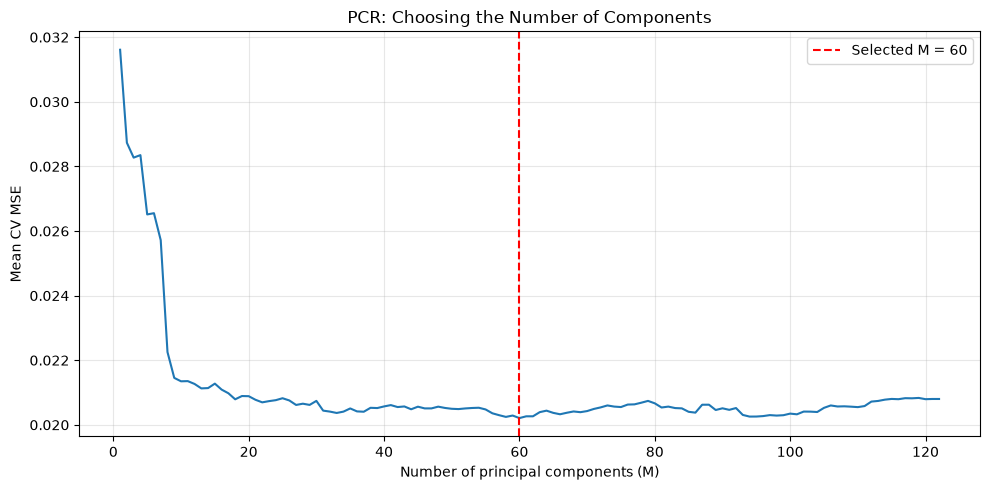

In [30]:
pcr_cv_results = pd.DataFrame({
    "M": [
        int(value)
        for value in pcr_search.cv_results_[
            "param_pca__n_components"
        ]
    ],
    "Mean CV MSE": -pcr_search.cv_results_["mean_test_score"],
}).sort_values("M")

plt.figure(figsize=(10, 5))

plt.plot(
    pcr_cv_results["M"],
    pcr_cv_results["Mean CV MSE"],
    linewidth=1.5,
)

plt.axvline(
    best_pcr_m,
    color="red",
    linestyle="--",
    label=f"Selected M = {best_pcr_m}",
)

plt.xlabel("Number of principal components (M)")
plt.ylabel("Mean CV MSE")
plt.title("PCR: Choosing the Number of Components")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### PCR Results

Cross-validation selected 60 principal components.
The mean validation MSE was 0.020210.

The test MSE was 0.018350, the test RMSE was 0.135460,
and the test R-squared was 0.614143.

The selected components captured 98.06% of the input variance.
However, PCR had a higher test MSE than OLS, Ridge, and both
LASSO models in this comparison.

PCA keeps directions with high input variance. These directions
are not always the most useful ones for predicting the target.

In [31]:
import xgboost
from xgboost import XGBRegressor

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1


### 2(j) XGBoost with L1 Regularization

I use XGBoost to fit a boosted tree model.
The model adds trees step by step to improve its predictions.

The parameter reg_alpha controls the L1 penalty on leaf weights.
This is different from fitting a separate LASSO model at each node.

I use five-fold cross-validation to choose alpha.
I keep 300 trees, a maximum depth of 3, and a learning rate of 0.05.
I set reg_lambda to 0 to turn off the L2 penalty.

Missing values are filled with training medians inside each fold.
I use the original feature scales without standardization.
The test set is used only for the final evaluation.

In [32]:
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", XGBRegressor(
        objective="reg:squarederror",
        booster="gbtree",
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=1.0,
        colsample_bytree=1.0,
        reg_lambda=0.0,
        tree_method="hist",
        random_state=42,
        n_jobs=1,
    )),
])

xgb_alphas = np.concatenate((
    [0.0],
    np.logspace(-4, 2, 25),
))

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid={"regressor__reg_alpha": xgb_alphas},
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=4,
    refit=True,
    error_score="raise",
)

xgb_search.fit(X_train, y_train)

xgb_model = xgb_search.best_estimator_
best_xgb_alpha = xgb_search.best_params_[
    "regressor__reg_alpha"
]

print("Best alpha:", best_xgb_alpha)
print(
    "Best mean CV MSE:",
    round(-xgb_search.best_score_, 6),
)
print(
    "Alpha at upper search boundary:",
    best_xgb_alpha == xgb_alphas[-1],
)

Best alpha: 0.31622776601683794
Best mean CV MSE: 0.020021
Alpha at upper search boundary: False


In [33]:
xgb_train_pred = xgb_model.predict(X_train)
xgb_test_pred = xgb_model.predict(X_test)

xgb_test_mse = mean_squared_error(y_test, xgb_test_pred)

regression_results["XGBoost"] = {
    "Train MSE": mean_squared_error(y_train, xgb_train_pred),
    "Test MSE": xgb_test_mse,
    "Test RMSE": np.sqrt(xgb_test_mse),
    "Test R2": r2_score(y_test, xgb_test_pred),
}

regression_summary = pd.DataFrame.from_dict(
    regression_results,
    orient="index",
)

display(regression_summary.round(6))

xgb_cv_results = pd.DataFrame({
    "alpha": [
        float(value)
        for value in xgb_search.cv_results_[
            "param_regressor__reg_alpha"
        ]
    ],
    "Mean CV MSE": -xgb_search.cv_results_["mean_test_score"],
}).sort_values("Mean CV MSE")

print("Top 10 alpha values by cross-validation:")
display(xgb_cv_results.head(10).round(6))

,Train MSE,Test MSE,Test RMSE,Test R2
OLS,0.016292,0.017966,0.134038,0.622204
Ridge,0.017317,0.017353,0.131731,0.635099
LASSO (unstandardized),0.017013,0.017615,0.132720,0.629597
LASSO (standardized),0.016903,0.017722,0.133123,0.627345
PCR,0.017939,0.018350,0.135460,0.614143
XGBoost,0.006155,0.016597,0.128828,0.651001


Top 10 alpha values by cross-validation:


,alpha,Mean CV MSE
15,0.316228,0.020021
17,1.000000,0.020075
14,0.177828,0.020118
16,0.562341,0.020119
13,0.100000,0.020145
18,1.778279,0.020314
12,0.056234,0.020323
11,0.031623,0.020335
10,0.017783,0.020384
19,3.162278,0.020410


#### XGBoost Results

Cross-validation selected an alpha of about 0.316228.
The mean validation MSE was 0.020021.

The training MSE was 0.006155.
The test MSE was 0.016597, the test RMSE was 0.128828,
and the test R-squared was 0.651001.

XGBoost had the lowest test MSE among the models tested.
However, its training MSE was much lower than its test MSE.
This gap suggests some overfitting.

### Final Model Comparison

| Model | Test MSE | Test RMSE | Test R-squared |
| --- | ---: | ---: | ---: |
| OLS | 0.017966 | 0.134038 | 0.622204 |
| Ridge | 0.017353 | 0.131731 | 0.635099 |
| LASSO (unstandardized) | 0.017615 | 0.132720 | 0.629597 |
| LASSO (standardized) | 0.017722 | 0.133123 | 0.627345 |
| PCR | 0.018350 | 0.135460 | 0.614143 |
| XGBoost | 0.016597 | 0.128828 | 0.651001 |

XGBoost had the lowest test MSE on this test set.
Ridge had the lowest test MSE among the linear models.

LASSO selected 74 variables without standardization and 76 with
standardization. Standardization did not improve its test MSE
in this case.

PCR used 60 principal components, but it had the highest test MSE
in this comparison.

The unstandardized LASSO had the lowest mean cross-validation MSE
among the tuned models. XGBoost had the lowest test MSE.
These results show that cross-validation and test rankings can differ.

I used cross-validation on the training set to choose model settings.
I did not use the test set to tune them.